# Supplemental Figure 1, Panel G

Log2 fold enrichment/depletion of BAFdep elements within enhancers, promoters, and insulators (defined based on chromHMM states)

*Output: panelG.pdf*

# Setup

In [1]:
#load packages 
library(tidyverse)
library(here)
here::i_am("figures/SuppFig1/PanelG/PanelG.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank()))
sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig1/PanelG

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      lubridate_1.9.4 forcats_1.0.0   stringr_1.5.1  
 [5] dplyr_1.1.4     purrr_1.0.2     readr_2.1.5     tidyr_1.3.1    
 [9] tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pillar_1.9.0      compiler_4.2.2    base64enc_0.1-3   

# Load data

In [2]:
# read in consensus peaks annotated by chromHMM state
data <- read.delim(
  here(
    "figures", "Figure1", "PanelE",
    "consensus_filt_annot_chromHMM.tsv"
  ),
  sep = "\t"
)

head(data)

# add annotations for BAF-dependence (defined as sig. decreased accessibility at 6h, 10µM)
bafdep <- read.delim(
  here("inputs", "DARs", "time_6h_DARs.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)
head(bafdep)
data$BAFdep <- bafdep$BAFdep

,seqnames,start,end,width,strand,name,chromHMM_state,TSS,chromHMM_state_slim,cRE_type
,<chr>,<int>,<int>,<int>,<chr>,<int>,<chr>,<lgl>,<chr>,<chr>
1,chr1,778362,779215,854,*,1,1_Active_Promoter,TRUE,Promoter,prom
2,chr1,804417,805076,660,*,2,5_Strong_Enhancer,FALSE,Enhancer,other_nonTSS
3,chr1,817195,817588,394,*,3,11_Weak_Txn,TRUE,Transcribed,other_TSS
4,chr1,826852,828112,1261,*,4,1_Active_Promoter,TRUE,Promoter,prom
5,chr1,838327,838675,349,*,5,7_Weak_Enhancer,FALSE,Enhancer,other_nonTSS
6,chr1,857921,859154,1234,*,6,6_Weak_Enhancer,TRUE,Enhancer,other_TSS


,seqnames,start,end,TSS,type,ID,logFC,logCPM,F,PValue,FDR,change,BAFdep
,<chr>,<int>,<int>,<lgl>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<lgl>
1,chr1,778361,779215,TRUE,prom,1,-0.02390158,6.967657,0.03179805,0.8611570567,0.918074042,nc,FALSE
2,chr1,804416,805076,FALSE,other_nonTSS,2,-1.24581970,4.617912,16.49118961,0.0005126174,0.001333570,down,TRUE
3,chr1,817194,817588,TRUE,other_TSS,3,-1.14649092,2.425637,9.22339590,0.0093176715,0.031459078,down,TRUE
4,chr1,826851,828112,TRUE,prom,4,0.05279976,7.965778,0.45201845,0.5128803611,0.663383442,nc,FALSE
5,chr1,838326,838675,FALSE,other_nonTSS,5,-1.71553715,2.744274,17.30499785,0.0004022144,0.001083655,down,TRUE
6,chr1,857920,859154,TRUE,other_TSS,6,-0.28991880,4.505674,1.26302334,0.2809401787,0.439516996,nc,FALSE


# Calculate fold enrichment

In [3]:
#calculate enrichment of chromHMM states in BAFdep regions
#background frequency of chromHMM state
background <- data %>% group_by(chromHMM_state_slim) %>% summarize(count=n(), .groups="drop") %>% summarize(chromHMM_state_slim, count, pct=100*count/sum(count))
#state frequency in BAFdep regions (6h, 10µM BAFinh)
BAFdep_only <- data %>% filter(BAFdep==TRUE) %>% group_by(chromHMM_state_slim) %>% summarize(count=n(), .groups="drop") %>% summarize(chromHMM_state_slim, count, pct=100*count/sum(count))
#log2FC enrichment 
fold_enr <- data.frame(state=background$chromHMM_state_slim, fc=BAFdep_only$pct/background$pct)

Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”


# Generate plot

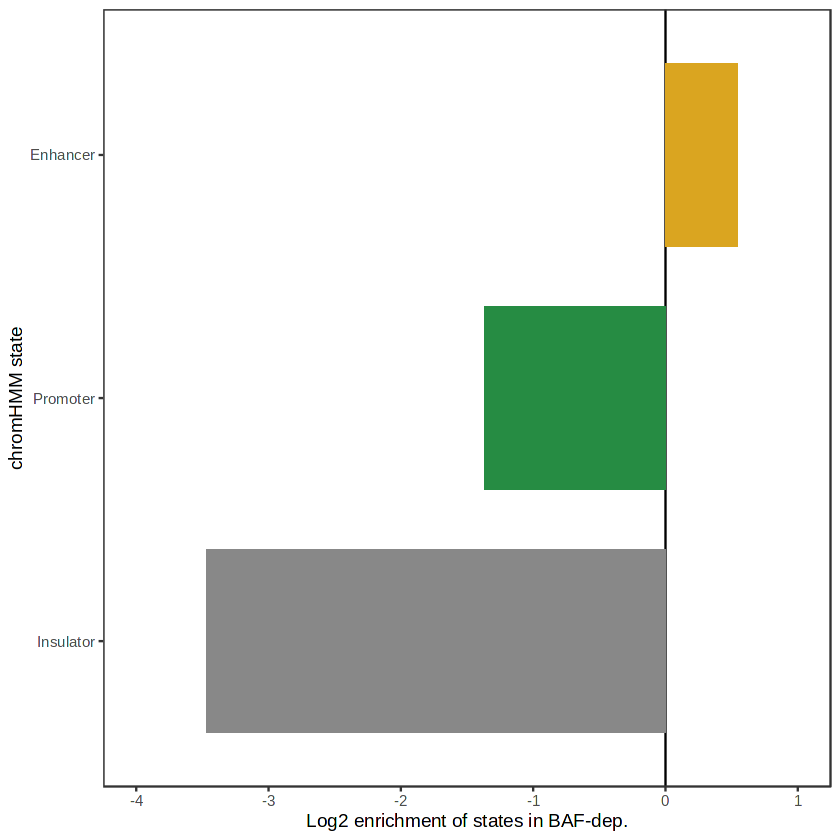

In [19]:
fold_enr %>%
    filter(state %in% c("Enhancer", "Promoter", "Insulator")) %>% 
    ggplot(aes(y=factor(state,levels=c("Insulator", "Promoter", "Enhancer")), fill=state,x=log2(fc))) + 
    geom_vline(xintercept=0) + 
    geom_col(width=.75, show.legend=F) + 
    xlab("Log2 enrichment of states in BAF-dep.") +
    ylab("chromHMM state") + 
    scale_fill_manual(values=c("Promoter"="#268c43", "Enhancer"="#daa520", "Insulator"="#888888")) +
    coord_cartesian(xlim=c(-4,1))
ggsave("panelG.pdf", height=2,width=3)

# Statistics (Fisher's exact test for enr. of enhancers for BAF-dep elements)

In [18]:
data %>% filter(chromHMM_state_slim %in% c("Enhancer", "Promoter", "Insulator")) %>% mutate(type=grepl("Enhancer",chromHMM_state)) %>% select(BAFdep, type) %>% table() %>% fisher.test()


	Fisher's Exact Test for Count Data

data:  .
p-value < 2.2e-16
alternative hypothesis: true odds ratio is not equal to 1
95 percent confidence interval:
 14.50509 15.60799
sample estimates:
odds ratio 
  15.04901 
